# FIREGUARD ID — 04: Advanced Density-Based Modeling (HDBSCAN)

            - Module: `src/models/hdbscan_model.py` using `sklearn.cluster.HDBSCAN` (`scikit-learn 1.7.2`).
            - Sweeps `min_cluster_size`, `min_samples`, `cluster_selection_method` (`eom`, `leaf`), and `cluster_selection_epsilon` from `config/models.yaml`.
            - **Non-Negotiable Noise Policy:** Never forces `-1` noise cells into clusters. Internal metrics are evaluated strictly via `compute_clustering_metrics(..., exclude_noise_label=-1)` on the non-noise core subset (`662 / 853` cells; `191` noise = `22.39%`).


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

import joblib
from src.evaluation.metrics import compute_clustering_metrics
from src.models.hdbscan_model import load_hdbscan_inputs, summarize_cluster_profiles, run_hdbscan_pipeline


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Load HDBSCAN Model, Assignments & Verify Guarded Metrics


In [2]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
models_dir = resolve_path(proj_cfg["paths"]["models_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)

df_scaled = pd.read_parquet(processed_dir / "clustering_matrix_scaled.parquet")
feat_cols = [c for c in df_scaled.columns if c != "grid_id"]
X = df_scaled[feat_cols].to_numpy(dtype=float)

df_hdb = pd.read_parquet(models_dir / "hdbscan" / "hdbscan_assignments.parquet")
hdb_model = joblib.load(models_dir / "hdbscan" / "hdbscan_model.joblib")
hdb_exp = json.loads((reports_dir / "clustering" / "hdbscan_experiments.json").read_text(encoding="utf-8"))

live_metrics = compute_clustering_metrics(X, df_hdb["cluster_hdbscan"].to_numpy(), exclude_noise_label=-1)
sel = hdb_exp["selected_configuration"]
print("Selected Params:", sel["params"])
print("Live Guarded Metrics (non-noise scope):", json.dumps(live_metrics, indent=2))
print("Subsample Stability ARI:", sel["subsample_stability"]["mean_ari_vs_full"])
print("Spatial-Fold Stability ARI:", sel["spatial_fold_stability"]["mean_ari_vs_full"])


Selected Params: {'min_cluster_size': 15, 'min_samples': 10, 'cluster_selection_method': 'eom', 'cluster_selection_epsilon': 0.0, 'metric': 'euclidean'}
Live Guarded Metrics (non-noise scope): {
  "n_total": 853,
  "n_valid_clustered": 662,
  "n_clusters": 8,
  "n_noise": 191,
  "noise_ratio": 0.223916,
  "valid_for_internal_metrics": true,
  "reason": "ok",
  "silhouette_score": 0.643293,
  "davies_bouldin_index": 0.882913,
  "calinski_harabasz_index": 1656.8601,
  "cluster_sizes": {
    "0": 249,
    "1": 46,
    "2": 77,
    "3": 92,
    "4": 91,
    "5": 30,
    "6": 39,
    "7": 38
  },
  "min_cluster_share": 0.045317,
  "max_cluster_share": 0.376133
}
Subsample Stability ARI: 0.971355
Spatial-Fold Stability ARI: 0.949771


## 2. Top Configurations & Cluster/Noise Size Distribution


,min_cluster_size,min_samples,cluster_selection_method,cluster_selection_epsilon,metric,n_clusters,noise_ratio,silhouette_nonnoise,dbi_nonnoise,spatial_fold_ari,score
0,15,10,eom,0.00,euclidean,8,0.223916,0.643293,0.882913,0.949771,0.804135
1,20,10,eom,0.00,euclidean,8,0.223916,0.643293,0.882913,0.945447,0.796778
2,10,15,eom,0.25,euclidean,7,0.228605,0.650472,0.883415,0.910678,0.724325
3,10,15,leaf,0.25,euclidean,7,0.228605,0.650472,0.883415,0.910678,0.724325
4,15,15,eom,0.25,euclidean,7,0.228605,0.650472,0.883415,0.905179,0.714969


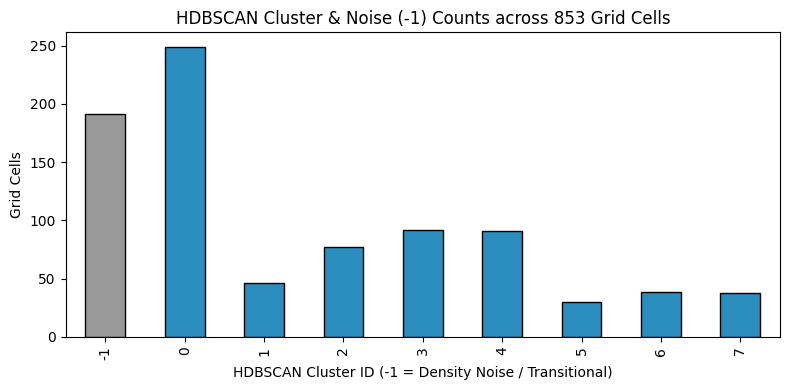

In [3]:
top5 = pd.DataFrame([
    {**r["params"], "n_clusters": r["n_clusters"], "noise_ratio": r["noise_ratio"],
     "silhouette_nonnoise": r["silhouette_score"], "dbi_nonnoise": r["davies_bouldin_index"],
     "spatial_fold_ari": r["spatial_fold_mean_ari"], "score": r["composite_selection_score"]}
    for r in hdb_exp["selection_summary"]["top_5_configs"]
])
display(top5)

counts = df_hdb["cluster_hdbscan"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#999999" if idx == -1 else "#2b8cbe" for idx in counts.index]
counts.plot(kind="bar", ax=ax, color=colors, edgecolor="black")
ax.set_title("HDBSCAN Cluster & Noise (-1) Counts across 853 Grid Cells")
ax.set_xlabel("HDBSCAN Cluster ID (-1 = Density Noise / Transitional)")
ax.set_ylabel("Grid Cells")
plt.tight_layout()
plt.show()
